In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from scipy.optimize import curve_fit
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [3]:
# Deterministic logistic model 
def logistic_model(t, r, K, P0):
    P =  (K * P0 * np.exp(r * t)) / (K + P0 * (np.exp(r * t) - 1))
    return P 

# Linearized model
def log_logistic_model(t, r, K, P0):
    return np.log(logistic_model(t, r, K, P0))

def linearized_logistic_model(t, r, K, P0):
    P = logistic_model(t, r, K, P0)
    return np.log(P/(K-P))

In [4]:
# Load cleaned weekly U.S. COVID-19 data
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "troyc03/COVID19-Logistic-Growth-Project/main/"
    "data/processed/us_covid_clean.csv"
)

df = pd.read_csv(DATA_URL, parse_dates=["week_ending"])

# Only retain observations where case reporting was available
df = df.loc[df["cases_reported"].astype(bool)].copy()

df = df.sort_values("week_ending").reset_index(drop=True)

print(df.head())
print(f"\nNumber of observations: {len(df)}")
print(f"Date range: {df.week_ending.min()} to {df.week_ending.max()}")


  week_ending  total_cases  total_deaths  new_cases  new_deaths  week  \
0  2020-01-26            7             0        7.0         0.0     0   
1  2020-02-02            9             0        2.0         0.0     1   
2  2020-02-09           20             0       11.0         0.0     2   
3  2020-02-16           24             0        4.0         0.0     3   
4  2020-02-23           40             0       16.0         0.0     4   

   cases_reported  
0            True  
1            True  
2            True  
3            True  
4            True  

Number of observations: 173
Date range: 2020-01-26 00:00:00 to 2023-05-14 00:00:00


Selected observations: 35
Initial cases: 33,368,900
Final cases: 78,334,128


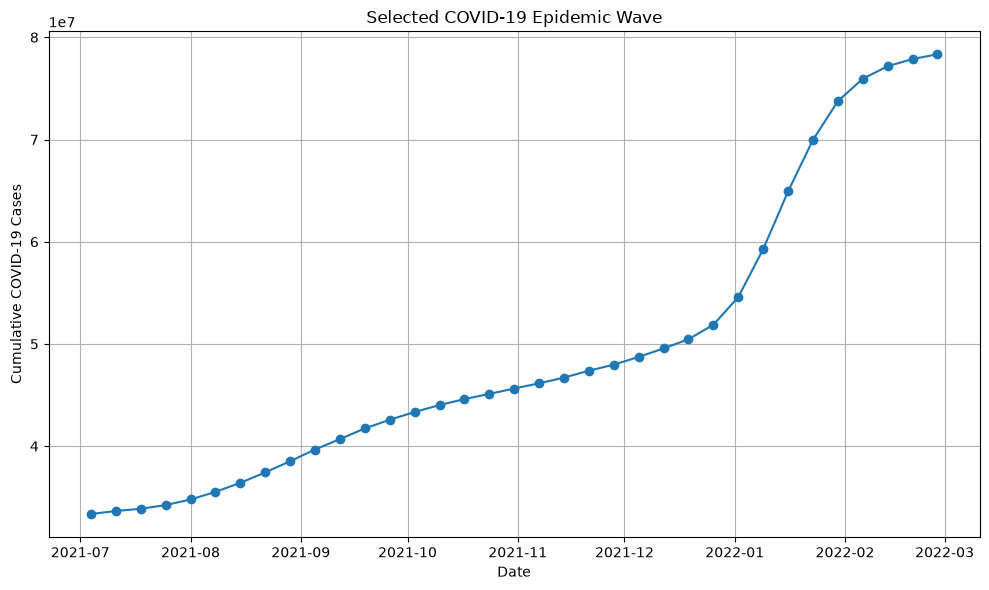

In [5]:
# EDIT THESE DATES TO SELECT YOUR EPIDEMIC WAVE

START_DATE = "2021-07-04"
END_DATE = "2022-02-27"

wave_df = df.loc[
    (df["week_ending"] >= START_DATE) &
    (df["week_ending"] <= END_DATE)
].copy()

wave_df = wave_df.reset_index(drop=True)

# Time measured in weeks from the first observation
t = np.arange(len(wave_df), dtype=float)

# Cumulative reported cases
P = wave_df["total_cases"].to_numpy(dtype=float)

if len(wave_df) < 8:
    raise ValueError("Select a wave containing at least 8 weekly observations.")

if np.any(np.diff(P) < 0):
    raise ValueError("Cumulative cases must be non-decreasing.")

P0 = P[0]

print(f"Selected observations: {len(P)}")
print(f"Initial cases: {P0:,.0f}")
print(f"Final cases: {P[-1]:,.0f}")

plt.figure(figsize=(10, 6))
plt.plot(wave_df["week_ending"], P, "o-")

plt.xlabel("Date")
plt.ylabel("Cumulative COVID-19 Cases")
plt.title("Selected COVID-19 Epidemic Wave")
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:

# Chronological training/testing split

test_size = 4

t_train = t[:-test_size]
P_train = P[:-test_size]

t_test = t[-test_size:]
P_test = P[-test_size:]

# Initial parameter estimates
K_guess = P_train[-1] * 1.2
r_guess = 0.15

initial_guess = [r_guess, K_guess]

# Parameter bounds:
# r > 0
# K > maximum observed training population

lower_bounds = [1e-8, P_train.max() * (1 + 1e-8)]
upper_bounds = [5.0, np.inf]

# Fit model using nonlinear least squares

def fitting_function(t, r, K):
    return logistic_model(t, r, K, P0)


estimated_parameters, covariance = curve_fit(
    fitting_function,
    t_train,
    P_train,
    p0=initial_guess,
    bounds=(lower_bounds, upper_bounds),
    maxfev=50000
)

est_r, est_K = estimated_parameters

# Parameter standard errors
standard_errors = np.sqrt(np.diag(covariance))

print("Estimated Logistic Parameters")
print("--------------------------------")
print(f"Growth rate (r): {est_r:.6f} per week")
print(f"Carrying capacity (K): {est_K:,.0f}")
print(f"Initial population (P0): {P0:,.0f}")

print("\nApproximate standard errors")
print(f"SE(r): {standard_errors[0]:.6f}")
print(f"SE(K): {standard_errors[1]:,.2f}")


Estimated Logistic Parameters
--------------------------------
Growth rate (r): 0.020917 per week
Carrying capacity (K): 705,586,603,972,750
Initial population (P0): 33,368,900

Approximate standard errors
SE(r): 0.000678
SE(K): 0.00


In [7]:

# Predictions
P_train_pred = logistic_model(
    t_train, est_r, est_K, P0
)

P_test_pred = logistic_model(
    t_test, est_r, est_K, P0
)

# Evaluation metrics
def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


train_metrics = calculate_metrics(
    P_train, P_train_pred
)

test_metrics = calculate_metrics(
    P_test, P_test_pred
)

metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Training", "Testing"]
)

print(metrics_df)


                   MAE          RMSE          R2
Training  2.424820e+06  3.480795e+06    0.882511
Testing   1.145899e+07  1.147986e+07 -161.241055


In [ ]:
# Refit using all observations in the selected wave

full_parameters, full_covariance = curve_fit(
    lambda t, r, K: logistic_model(t, r, K, P0),
    t,
    P,
    p0=estimated_parameters,
    bounds=(lower_bounds, upper_bounds),
    maxfev=50000
)

final_r, final_K = full_parameters

# Forecast 1, 2, and 4 weeks beyond the selected wave
forecast_steps = np.array([1, 2, 4])

future_t = np.array([
    len(t) - 1 + step
    for step in forecast_steps
], dtype=float)

forecast_values = logistic_model(
    future_t,
    final_r,
    final_K,
    P0
)

forecast_dates = [
    wave_df["week_ending"].iloc[-1]
    + pd.Timedelta(weeks=int(step))
    for step in forecast_steps
]

forecast_df = pd.DataFrame({
    "Date": forecast_dates,
    "Weeks_Ahead": forecast_steps,
    "Predicted_Cumulative_Cases": forecast_values
})

print(forecast_df.to_string(index=False))


      Date  Weeks_Ahead  Predicted_Cumulative_Cases
2022-03-06            1                7.467812e+07
2022-03-13            2                7.641685e+07
2022-03-27            4                8.001670e+07


In [ ]:

# Export estimated parameters

parameter_df = pd.DataFrame({
    "Parameter": ["r", "K", "P0"],
    "Estimate": [final_r, final_K, P0]
})

parameter_df.to_csv(
    "estimated_parameters.csv",
    index=False
)

# Export model evaluation metrics
metrics_df.to_csv(
    "model_metrics.csv"
)

# Export forecasts
forecast_df.to_csv(
    "forecast_predictions.csv",
    index=False
)

print("Successfully exported:")
print("- estimated_parameters.csv")
print("- model_metrics.csv")
print("- forecast_predictions.csv")
